# XGBoost Baseline — Sinhala Hate Speech Detection on Noisy Text

This notebook implements the **traditional ML baseline (Section 5.3.1)** of the project proposal,
using **XGBoost**, trained and tested on noisy text (`noisy_text` field). The noise **condition**
(transliteration, codemix, misspelling, abbreviation, ...) is set in **Section 2** via the
`CONDITION` variable — everything else in the notebook is condition-agnostic and works unchanged.



**What this notebook does, matching the proposal exactly:**
- Trains and evaluates separately on **light** and **heavy** noise severity (Section 5.1.2).
- Uses only the feature representation Section 5.3.1 specifies: **character n-gram (1-5) TF-IDF**
  and **word n-gram (1-2) TF-IDF**.
- Handles **class imbalance** (proposal notes ~41% offensive) via `scale_pos_weight`.
- Tunes hyperparameters with **leakage-safe** cross-validation (TF-IDF refit per fold).
- Reports **macro-F1**, per-class precision/recall/F1, weighted F1, confusion matrix, and compares
  against a majority-class baseline (Section 5.4.1).
- Saves the trained pipeline (vectorizers + model together) and result tables back to Google Drive.
- Includes extended analysis (Sections 12-19): ROC/PR curves, bootstrap confidence intervals,
  McNemar's test, OOV/fragmentation analysis, feature importance, and qualitative error examples.

**Colab free-tier friendly:** refitting TF-IDF inside every CV fold is more expensive than fitting
it once, so this notebook uses a **disk cache** (`Pipeline(memory=...)`) so that repeated
hyperparameter candidates which only change the XGBoost settings (not the TF-IDF settings) reuse
the already-computed TF-IDF features for that fold instead of recomputing them. GPU is
auto-detected and used if available, but not required.


## 1. Setup — install packages

In [ ]:
!pip install -q --upgrade xgboost scikit-learn scipy joblib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 108.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.4/252.4 MB 5.6 MB/s eta 0:00:00


## 2. Mount Google Drive and set paths

**This is the only place you need to edit to switch noise conditions (transliteration, codemix, misspelling, abbreviation, ...).** Set `CONDITION` to match your Drive folder name and your file-name prefix — everything else in this notebook (feature engineering, training, evaluation, analysis) reads from `TRAIN_FILES`/`TEST_FILES`/`RESULTS_DIR` and works unchanged regardless of which condition you point it at.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# ======================================================================
# >>> EDIT ONLY THIS SECTION to switch noise conditions <<<
# ======================================================================
# CONDITION must match:
#   (a) the Drive folder name that holds train/ and test/ for this noise type, and
#   (b) the prefix used in the .jsonl file names inside those folders.
# e.g. for transliteration: folder "transliterations", files "transliteration_light.jsonl"
#      for codemix:         folder "codemix",          files "codemix_light.jsonl"

CONDITION = "codemix"          # <-- change this per noise condition
DATA_FOLDER_NAME = "codemix"   # <-- change this if the Drive folder name differs from CONDITION
# ======================================================================

BASE_DIR = f"/content/drive/MyDrive/{DATA_FOLDER_NAME}"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
TEST_DIR  = os.path.join(BASE_DIR, "test")
RESULTS_DIR = os.path.join(BASE_DIR, "results", "xgboost")
os.makedirs(RESULTS_DIR, exist_ok=True)

SEVERITIES = ["light", "heavy"]   # {CONDITION}_light.jsonl / {CONDITION}_heavy.jsonl

TRAIN_FILES = {sev: os.path.join(TRAIN_DIR, f"{CONDITION}_{sev}.jsonl") for sev in SEVERITIES}
TEST_FILES  = {sev: os.path.join(TEST_DIR,  f"{CONDITION}_{sev}.jsonl") for sev in SEVERITIES}

print(f"Condition: {CONDITION} | Data folder: {DATA_FOLDER_NAME}\n")
for sev in SEVERITIES:
    print(sev, "train:", TRAIN_FILES[sev], os.path.exists(TRAIN_FILES[sev]))
    print(sev, "test :", TEST_FILES[sev],  os.path.exists(TEST_FILES[sev]))


Mounted at /content/drive
Condition: codemix | Data folder: codemix

light train: /content/drive/MyDrive/codemix/train/codemix_light.jsonl True
light test : /content/drive/MyDrive/codemix/test/codemix_light.jsonl True
heavy train: /content/drive/MyDrive/codemix/train/codemix_heavy.jsonl True
heavy test : /content/drive/MyDrive/codemix/test/codemix_heavy.jsonl True


## 3. Imports

In [ ]:
import json
import shutil
import tempfile
import warnings
import numpy as np
import pandas as pd
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, f1_score, precision_recall_fscore_support,
    confusion_matrix, accuracy_score
)
from scipy.stats import randint, uniform

import xgboost as xgb

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Detect GPU for XGBoost (optional -- code works fine on CPU-only Colab too)
try:
    import subprocess
    _gpu_ok = subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
except Exception:
    _gpu_ok = False

XGB_DEVICE = "cuda" if _gpu_ok else "cpu"
XGB_TREE_METHOD = "hist"
print("XGBoost device:", XGB_DEVICE)


XGBoost device: cuda


## 4. Load the noisy JSONL data

We train and test using the **`noisy_text`** field (not `original_text`) — the model only ever sees noisy transliterated text.

In [ ]:
def load_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rows.append(json.loads(line))
    return pd.DataFrame(rows)

data = {}
for sev in SEVERITIES:
    data[sev] = {
        "train": load_jsonl(TRAIN_FILES[sev]),
        "test":  load_jsonl(TEST_FILES[sev]),
    }
    for split in ("train", "test"):
        df = data[sev][split]
        assert "noisy_text" in df.columns and "label" in df.columns, \
            f"Missing expected columns in {sev}/{split}"
        df["noisy_text"] = df["noisy_text"].astype(str)
        df["label"] = df["label"].astype(int)
    print(f"[{sev}] train: {len(data[sev]['train'])} rows | test: {len(data[sev]['test'])} rows")
    print(f"[{sev}] train label distribution:\n{data[sev]['train']['label'].value_counts(normalize=True)}")


[light] train: 7500 rows | test: 2500 rows
[light] train label distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64
[heavy] train: 7500 rows | test: 2500 rows
[heavy] train label distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64


## 5. Feature engineering

Per Section 5.3.1: **character n-gram (1-5) TF-IDF** + **word n-gram (1-2) TF-IDF**, nothing else.

The key change: instead of calling `.fit_transform()` on the whole training set up front, both
TF-IDF vectorizers are wrapped inside a `FeatureUnion`, which is itself the first step of a
`Pipeline` whose last step is the XGBoost classifier. When this pipeline is handed to
`RandomizedSearchCV` with **raw text** (not a pre-built matrix), scikit-learn clones and refits
the *entire* pipeline — including both TF-IDF vectorizers — separately on each CV fold's training
portion. The held-out fold's text never touches vectorizer fitting for that fold. This removes the
TF-IDF leakage.

A `memory` cache is attached to the pipeline so that when `RandomizedSearchCV` tries different
XGBoost hyperparameters on the *same* fold, it doesn't needlessly recompute the (unchanged) TF-IDF
features every single time — only re-run the classifier step. This keeps things fast enough for
Colab's free tier despite the extra refitting.


In [ ]:
_cache_dir = tempfile.mkdtemp(prefix="tfidf_cache_")

def build_pipeline(scale_pos_weight, cache_dir=_cache_dir):
    char_vec = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(1, 5),
        min_df=2,
        max_features=30000,
        sublinear_tf=True,
    )
    word_vec = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=15000,
        sublinear_tf=True,
        token_pattern=r"(?u)\b\w+\b",
    )
    features = FeatureUnion([
        ("char_tfidf", char_vec),
        ("word_tfidf", word_vec),
    ])

    clf = xgb.XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method=XGB_TREE_METHOD,
        device=XGB_DEVICE,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        scale_pos_weight=scale_pos_weight,
    )

    pipe = Pipeline(
        [("features", features), ("clf", clf)],
        memory=cache_dir,  # caches the (expensive, fold-specific) TF-IDF output
    )
    return pipe


## 6. Hyperparameter tuning + training (per severity)

`RandomizedSearchCV` now receives **raw noisy text** (`train_df["noisy_text"].values`), not a
pre-built feature matrix. It internally splits the raw text into 5 stratified folds, and for each
fold, clones and fits the *whole pipeline* (TF-IDF + XGBoost) using only that fold's training
portion, then scores it on the held-out portion. `scale_pos_weight` is computed once from the full
training label distribution (this only uses labels, not text/features, so it is not a source of
feature leakage).


In [ ]:
def train_xgb_for_severity(sev, n_iter=20, cv_folds=5):
    print(f"\n{'='*70}\nTraining XGBoost on '{sev}' {CONDITION} noise\n{'='*70}")

    train_df = data[sev]["train"].reset_index(drop=True)
    test_df  = data[sev]["test"].reset_index(drop=True)

    X_train_text = train_df["noisy_text"].values
    y_train = train_df["label"].values
    X_test_text = test_df["noisy_text"].values
    y_test  = test_df["label"].values

    n_pos = (y_train == 1).sum()
    n_neg = (y_train == 0).sum()
    spw = n_neg / max(n_pos, 1)
    print(f"Class balance -> not-offensive: {n_neg}, offensive: {n_pos}, scale_pos_weight={spw:.3f}")

    pipe = build_pipeline(scale_pos_weight=spw)

    param_dist = {
        "clf__n_estimators": randint(150, 600),
        "clf__max_depth": randint(3, 10),
        "clf__learning_rate": uniform(0.01, 0.29),
        "clf__subsample": uniform(0.6, 0.4),
        "clf__colsample_bytree": uniform(0.5, 0.5),
        "clf__min_child_weight": randint(1, 8),
        "clf__gamma": uniform(0, 0.5),
        "clf__reg_alpha": uniform(0, 1.0),
        "clf__reg_lambda": uniform(0.5, 2.0),
    }

    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring="f1_macro",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
    )
    # NOTE: raw text goes in here, not a pre-built TF-IDF matrix.
    # RandomizedSearchCV + Pipeline handles fold-wise TF-IDF fitting internally.
    search.fit(X_train_text, y_train)

    print("Best CV macro-F1:", round(search.best_score_, 4))
    print("Best params:", search.best_params_)

    best_pipeline = search.best_estimator_  # already refit on the FULL training set by RandomizedSearchCV (refit=True default)

    artifacts = {
        "pipeline": best_pipeline,
        "best_params": search.best_params_,
        "cv_macro_f1": search.best_score_,
    }
    return artifacts, X_test_text, y_test, test_df


## 7. Evaluation (matches Section 5.4.1 / 5.4.2)

Same as before: macro-F1, per-class precision/recall/F1, weighted F1, confusion matrix, and a
majority-class baseline comparison. The fitted pipeline handles the raw-text -> TF-IDF ->
prediction steps in one call, using the vectorizers it fit on the full training set (this final
refit-on-everything step, done once after hyperparameter selection, is standard and not leakage —
leakage only concerns what happens *during* cross-validation/model selection).


In [ ]:
def evaluate(artifacts, X_test_text, y_test, test_df, sev):
    pipeline = artifacts["pipeline"]
    y_pred = pipeline.predict(X_test_text)

    macro_f1 = f1_score(y_test, y_pred, average="macro")
    weighted_f1 = f1_score(y_test, y_pred, average="weighted")
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, support = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1])

    print(f"\n--- Results: severity = {sev} ---")
    print(f"Accuracy     : {acc:.4f}")
    print(f"Macro-F1     : {macro_f1:.4f}")
    print(f"Weighted-F1  : {weighted_f1:.4f}")
    print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["not-offensive", "offensive"], digits=4))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print("Confusion matrix [rows=true, cols=pred] (0=not-offensive, 1=offensive):")
    print(cm)

    dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
    dummy.fit(X_test_text.reshape(-1, 1), y_test)
    y_dummy = dummy.predict(X_test_text.reshape(-1, 1))
    dummy_f1 = f1_score(y_test, y_dummy, average="macro")
    print(f"Majority-class baseline macro-F1: {dummy_f1:.4f}")

    results_row = {
        "severity": sev,
        "accuracy": acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "precision_not_offensive": prec[0], "recall_not_offensive": rec[0], "f1_not_offensive": f1[0],
        "precision_offensive": prec[1], "recall_offensive": rec[1], "f1_offensive": f1[1],
        "support_not_offensive": int(support[0]), "support_offensive": int(support[1]),
        "majority_baseline_macro_f1": dummy_f1,
        "cv_macro_f1": artifacts["cv_macro_f1"],
        "best_params": artifacts["best_params"],
    }

    preds_df = test_df.copy()
    preds_df["predicted_label"] = y_pred
    preds_df["predicted_proba_offensive"] = pipeline.predict_proba(X_test_text)[:, 1]

    return results_row, preds_df, cm


## 8. Run the full pipeline for both severities and save everything to Drive

In [ ]:
all_results = []
all_cms = {}
all_artifacts = {}

for sev in SEVERITIES:
    artifacts, X_test_text, y_test, test_df = train_xgb_for_severity(sev, n_iter=20, cv_folds=5)
    results_row, preds_df, cm = evaluate(artifacts, X_test_text, y_test, test_df, sev)
    all_results.append(results_row)
    all_cms[sev] = cm
    all_artifacts[sev] = artifacts

    # --- save the whole pipeline (vectorizers + model together) for this severity ---
    model_path = os.path.join(RESULTS_DIR, f"xgboost_pipeline_{sev}.joblib")
    joblib.dump(artifacts["pipeline"], model_path)
    print(f"Saved pipeline -> {model_path}")

    # --- save test predictions ---
    preds_path = os.path.join(RESULTS_DIR, f"test_predictions_{sev}.csv")
    preds_df.to_csv(preds_path, index=False)
    print(f"Saved predictions -> {preds_path}")

# --- save summary results table ---
results_df = pd.DataFrame(all_results)
results_path = os.path.join(RESULTS_DIR, "xgboost_results_summary.csv")
results_df.to_csv(results_path, index=False)
print(f"\nSaved results summary -> {results_path}")
results_df



Training XGBoost on 'light' codemix noise
Class balance -> not-offensive: 4324, offensive: 3176, scale_pos_weight=1.361
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV macro-F1: 0.8109
Best params: {'clf__colsample_bytree': np.float64(0.8047821669899484), 'clf__gamma': np.float64(0.25133951161443074), 'clf__learning_rate': np.float64(0.02492883786249691), 'clf__max_depth': 7, 'clf__min_child_weight': 1, 'clf__n_estimators': 534, 'clf__reg_alpha': np.float64(0.23956189066697242), 'clf__reg_lambda': np.float64(0.7897897441824462), 'clf__subsample': np.float64(0.7957811041110252)}

--- Results: severity = light ---
Accuracy     : 0.8204
Macro-F1     : 0.8107
Weighted-F1  : 0.8187
               precision    recall  f1-score   support

not-offensive     0.8274    0.8815    0.8536      1485
    offensive     0.8083    0.7310    0.7677      1015

     accuracy                         0.8204      2500
    macro avg     0.8179    0.8063    0.8107      2500
 weighted avg 

,severity,accuracy,macro_f1,weighted_f1,precision_not_offensive,recall_not_offensive,f1_not_offensive,precision_offensive,recall_offensive,f1_offensive,support_not_offensive,support_offensive,majority_baseline_macro_f1,cv_macro_f1,best_params
0,light,0.8204,0.810661,0.818734,0.827434,0.881481,0.853603,0.808279,0.731034,0.767719,1485,1015,0.372647,0.810896,"{'clf__colsample_bytree': 0.8047821669899484, ..."
1,heavy,0.8172,0.807580,0.815668,0.826557,0.876094,0.850605,0.801296,0.731034,0.764554,1485,1015,0.372647,0.811275,"{'clf__colsample_bytree': 0.8047821669899484, ..."


## 9. Degradation check: does heavy noise hurt more than light noise?

In [ ]:
if set(SEVERITIES) == {"light", "heavy"}:
    f1_light = results_df.loc[results_df.severity == "light", "macro_f1"].values[0]
    f1_heavy = results_df.loc[results_df.severity == "heavy", "macro_f1"].values[0]
    drop = f1_light - f1_heavy
    print(f"Macro-F1 (light noise): {f1_light:.4f}")
    print(f"Macro-F1 (heavy noise): {f1_heavy:.4f}")
    print(f"Performance drop (light -> heavy): {drop:.4f}  "
          f"({'heavier noise hurts more' if drop > 0 else 'no clear extra degradation from heavier noise'})")


Macro-F1 (light noise): 0.8107
Macro-F1 (heavy noise): 0.8076
Performance drop (light -> heavy): 0.0031  (heavier noise hurts more)


## 10. (Optional) Feature importance — which signals matter most?

In [ ]:
import matplotlib.pyplot as plt

def show_top_features(sev, top_n=20):
    pipeline = all_artifacts[sev]["pipeline"]
    feature_union = pipeline.named_steps["features"]
    model = pipeline.named_steps["clf"]

    all_names = feature_union.get_feature_names_out()
    importances = model.feature_importances_
    order = np.argsort(importances)[::-1][:top_n]

    top_feats = pd.DataFrame({
        "feature": all_names[order],
        "importance": importances[order],
    })
    print(f"Top {top_n} features for severity='{sev}':")
    display(top_feats)

    plt.figure(figsize=(8, 6))
    plt.barh(top_feats["feature"][::-1], top_feats["importance"][::-1])
    plt.title(f"Top {top_n} XGBoost feature importances ({sev} noise)")
    plt.xlabel("importance")
    plt.tight_layout()
    plt.show()

# Example:
# show_top_features("heavy")
# show_top_features("light")


## 11. Clean up the TF-IDF disk cache

In [ ]:
shutil.rmtree(_cache_dir, ignore_errors=True)
print("Removed TF-IDF cache directory:", _cache_dir)


Removed TF-IDF cache directory: /tmp/tfidf_cache_3zx8bygq


---
# Additional Analysis (for the research paper)

Everything below is **read-only analysis** on top of the models already trained and evaluated in
Sections 1–11 above — nothing here retrains anything, changes any hyperparameter, or touches the
existing pipelines/results in any way. It reuses `all_artifacts` (the fitted pipelines) and `data`
(the loaded DataFrames) exactly as they already exist in memory after running Section 8, so your
accuracy/macro-F1/etc. numbers are unaffected. Run Sections 1–11 first, then run everything below.

**What's added:**
1. Confusion matrix heatmaps (visual version of the matrices already printed in Section 8)
2. ROC curves + AUC, and Precision–Recall curves + Average Precision, light vs. heavy
3. Bootstrap 95% confidence intervals for macro-F1 (per Section 5.4.1's call for statistical
   confidence, without needing to retrain across multiple seeds)
4. McNemar's exact test comparing light vs. heavy predictions on matched posts (same underlying
   post, different noise severity) — directly tests whether noise severity significantly changes
   per-post correctness, per the proposal's Section 5.4.1 statistical testing requirement
5. A tokenization-fragmentation proxy: out-of-vocabulary (OOV) character n-gram rate per post,
   compared between severities and between correct/incorrect predictions — speaks to the
   proposal's Section 5.4.2 fragmentation analysis
6. Actually running the feature-importance inspection (`show_top_features`, defined in Section 10
   but not previously called)
7. Qualitative error analysis: sampled false positives and false negatives with predicted
   probabilities, for both severities
8. Saving all new plots/tables to Drive under `results/xgboost/analysis/`


## 12. Recompute predictions per severity for analysis (no retraining — same fitted pipelines)

In [ ]:
import os

ANALYSIS_DIR = os.path.join(RESULTS_DIR, "analysis")
os.makedirs(ANALYSIS_DIR, exist_ok=True)

# Rebuild per-severity test arrays + predictions directly from the already-fitted pipelines
# in `all_artifacts` and the already-loaded `data` dict. This does NOT retrain or refit anything —
# `pipeline.predict(...)` on an already-fitted pipeline is deterministic and reproduces the exact
# same predictions already computed in Section 8.
analysis = {}
for sev in SEVERITIES:
    test_df = data[sev]["test"].reset_index(drop=True)
    X_text = test_df["noisy_text"].values
    y_true = test_df["label"].values

    pipeline = all_artifacts[sev]["pipeline"]
    y_pred = pipeline.predict(X_text)
    y_proba = pipeline.predict_proba(X_text)[:, 1]

    analysis[sev] = {
        "test_df": test_df,
        "X_text": X_text,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_proba": y_proba,
    }

    # sanity check: these should match the macro-F1 already reported in Section 8
    check_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"[{sev}] recomputed macro-F1 = {check_f1:.4f}  "
          f"(should match Section 8's reported value exactly)")


[light] recomputed macro-F1 = 0.8107  (should match Section 8's reported value exactly)
[heavy] recomputed macro-F1 = 0.8076  (should match Section 8's reported value exactly)


## 13. Confusion matrix heatmaps

Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/confusion_matrices.png


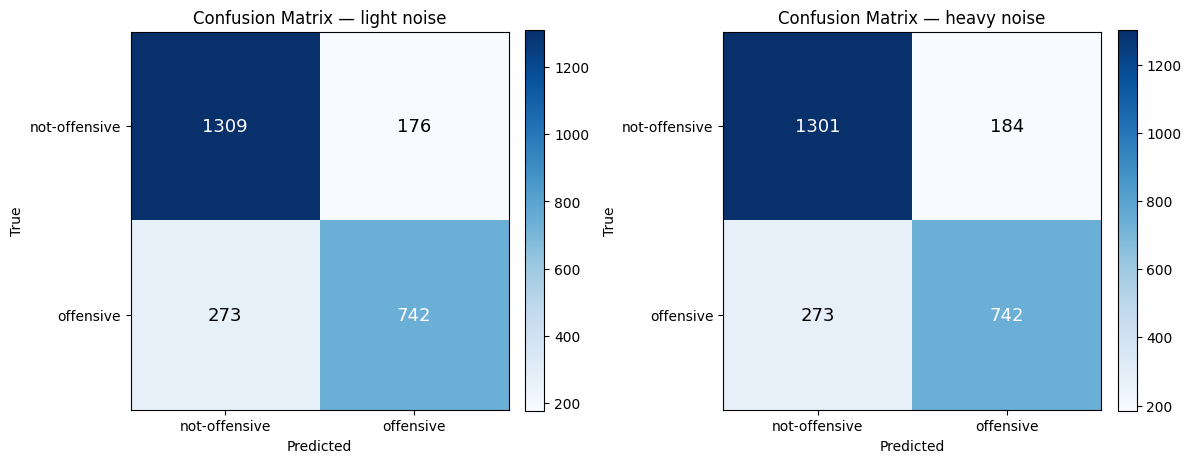

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(SEVERITIES), figsize=(6 * len(SEVERITIES), 5))
if len(SEVERITIES) == 1:
    axes = [axes]

for ax, sev in zip(axes, SEVERITIES):
    cm = all_cms[sev]
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Confusion Matrix — {sev} noise")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["not-offensive", "offensive"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["not-offensive", "offensive"])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
cm_path = os.path.join(ANALYSIS_DIR, "confusion_matrices.png")
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {cm_path}")
plt.show()


## 14. ROC curves + AUC, Precision-Recall curves + Average Precision

These use the model's predicted *probability* of the offensive class (not just the hard
0/1 prediction), so they show performance across all possible decision thresholds — useful for
the paper if you want to discuss threshold choice, or just as a standard reported metric alongside
macro-F1.


Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/roc_pr_curves.png


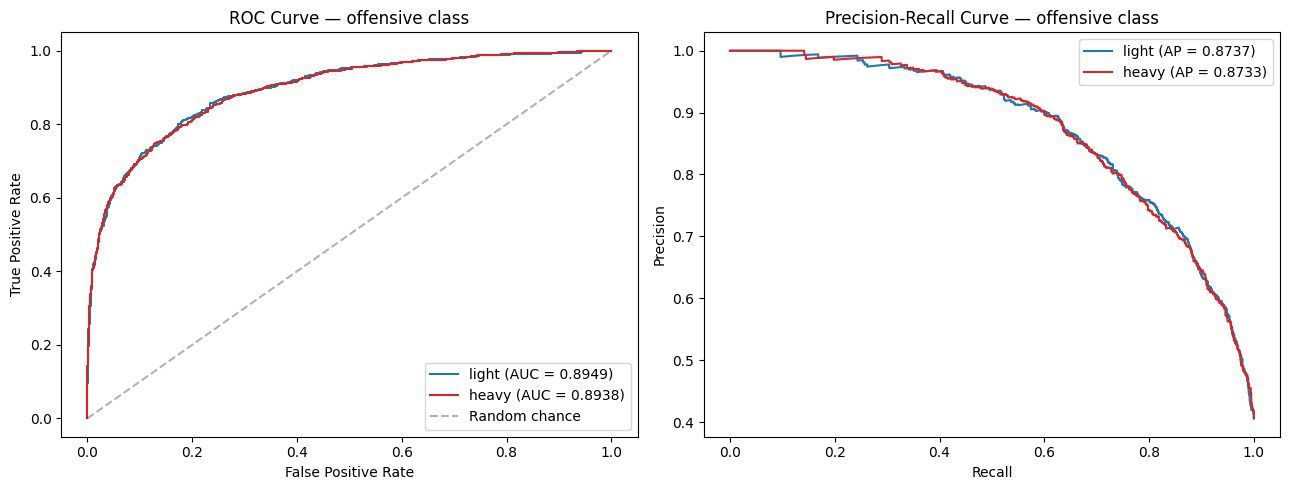


ROC AUC by severity: {'light': 0.8948519679554163, 'heavy': 0.8938149972632732}
Average Precision by severity: {'light': 0.8736644779288448, 'heavy': 0.8732624017451338}


In [ ]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
roc_auc_scores = {}
ap_scores = {}

colors = {"light": "tab:blue", "heavy": "tab:red"}

for sev in SEVERITIES:
    y_true = analysis[sev]["y_true"]
    y_proba = analysis[sev]["y_proba"]

    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    roc_auc_scores[sev] = roc_auc
    ax1.plot(fpr, tpr, label=f"{sev} (AUC = {roc_auc:.4f})", color=colors.get(sev))

    prec, rec, _ = precision_recall_curve(y_true, y_proba)
    ap = average_precision_score(y_true, y_proba)
    ap_scores[sev] = ap
    ax2.plot(rec, prec, label=f"{sev} (AP = {ap:.4f})", color=colors.get(sev))

ax1.plot([0, 1], [0, 1], "k--", alpha=0.3, label="Random chance")
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
ax1.set_title("ROC Curve — offensive class"); ax1.legend()

ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax2.set_title("Precision-Recall Curve — offensive class"); ax2.legend()

plt.tight_layout()
roc_pr_path = os.path.join(ANALYSIS_DIR, "roc_pr_curves.png")
plt.savefig(roc_pr_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {roc_pr_path}")
plt.show()

print("\nROC AUC by severity:", roc_auc_scores)
print("Average Precision by severity:", ap_scores)


## 15. Bootstrap 95% confidence intervals for macro-F1

The proposal's Section 5.4.1 calls for reporting results with confidence intervals (originally
via repeating training across 5 random seeds). Retraining 5x is expensive on Colab's free tier, so
as a lighter-weight alternative this resamples the **already-predicted test set** with replacement
many times and recomputes macro-F1 each time, giving a 95% confidence interval around the reported
score. This does not change your point-estimate macro-F1 at all — it only quantifies how much that
number might reasonably vary due to which specific posts happen to be in the test set.


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
N_BOOTSTRAP = 2000

bootstrap_results = {}
for sev in SEVERITIES:
    y_true = analysis[sev]["y_true"]
    y_pred = analysis[sev]["y_pred"]
    n = len(y_true)

    boot_scores = np.empty(N_BOOTSTRAP)
    for i in range(N_BOOTSTRAP):
        idx = rng.integers(0, n, n)
        boot_scores[i] = f1_score(y_true[idx], y_pred[idx], average="macro")

    point_estimate = f1_score(y_true, y_pred, average="macro")
    ci_low, ci_high = np.percentile(boot_scores, [2.5, 97.5])
    bootstrap_results[sev] = {
        "macro_f1": point_estimate,
        "ci_low_95": ci_low,
        "ci_high_95": ci_high,
        "bootstrap_std": boot_scores.std(),
    }
    print(f"[{sev}] macro-F1 = {point_estimate:.4f}, "
          f"95% CI = [{ci_low:.4f}, {ci_high:.4f}], "
          f"bootstrap std = {boot_scores.std():.4f}")

bootstrap_df = pd.DataFrame(bootstrap_results).T
bootstrap_path = os.path.join(ANALYSIS_DIR, "bootstrap_confidence_intervals.csv")
bootstrap_df.to_csv(bootstrap_path)
print(f"\nSaved -> {bootstrap_path}")
bootstrap_df


[light] macro-F1 = 0.8107, 95% CI = [0.7948, 0.8257], bootstrap std = 0.0077
[heavy] macro-F1 = 0.8076, 95% CI = [0.7910, 0.8232], bootstrap std = 0.0082

Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/bootstrap_confidence_intervals.csv


,macro_f1,ci_low_95,ci_high_95,bootstrap_std
light,0.810661,0.794827,0.825654,0.007684
heavy,0.807580,0.790984,0.823194,0.008201


## 16. McNemar's exact test: does noise severity significantly change per-post correctness?

The proposal's Section 5.4.1 specifies McNemar's test to confirm differences between conditions
are real rather than chance. Light and heavy test sets contain **the same underlying posts**
(matched by `source_id`), just noised at different severities — so each post gives a matched pair
of predictions, one under light noise and one under heavy noise. McNemar's test looks only at the
posts where the two severities *disagree* (correct under one, wrong under the other) and tests
whether that disagreement is skewed in one direction more than chance would allow.


In [ ]:
if len(SEVERITIES) == 2 and set(SEVERITIES) == {"light", "heavy"}:
    df_light = analysis["light"]["test_df"][["source_id", "label"]].copy()
    df_light["pred_light"] = analysis["light"]["y_pred"]
    df_heavy = analysis["heavy"]["test_df"][["source_id", "label"]].copy()
    df_heavy["pred_heavy"] = analysis["heavy"]["y_pred"]

    merged = df_light.merge(df_heavy, on=["source_id", "label"], how="inner")
    print(f"Matched posts across light/heavy by source_id: {len(merged)} "
          f"(light test set had {len(df_light)}, heavy had {len(df_heavy)})")

    if len(merged) == 0:
        print("No matching source_id values found between light and heavy test sets -- "
              "McNemar's test needs the SAME underlying posts in both severities to be meaningful. "
              "Skipping.")
    else:
        merged["correct_light"] = merged["pred_light"] == merged["label"]
        merged["correct_heavy"] = merged["pred_heavy"] == merged["label"]

        b = int(((merged["correct_light"]) & (~merged["correct_heavy"])).sum())  # light right, heavy wrong
        c = int(((~merged["correct_light"]) & (merged["correct_heavy"])).sum())  # light wrong, heavy right
        both_right = int((merged["correct_light"] & merged["correct_heavy"]).sum())
        both_wrong = int((~merged["correct_light"] & ~merged["correct_heavy"]).sum())

        print(f"\nContingency: both correct={both_right}, both wrong={both_wrong}, "
              f"light-only-correct(b)={b}, heavy-only-correct(c)={c}")

        n_discordant = b + c
        if n_discordant == 0:
            print("No discordant pairs -- light and heavy have identical per-post correctness. "
                  "McNemar's test is not applicable (no evidence of a severity effect either way).")
        else:
            from scipy.stats import binomtest
            mcnemar_result = binomtest(min(b, c), n_discordant, 0.5, alternative="two-sided")
            print(f"\nMcNemar's exact test: n_discordant={n_discordant}, p-value={mcnemar_result.pvalue:.4f}")
            alpha = 0.05
            if mcnemar_result.pvalue < alpha:
                direction = "light noise" if b > c else "heavy noise"
                print(f"Result is statistically significant at alpha={alpha}: predictions are "
                      f"significantly more often correct under {direction} for these matched posts.")
            else:
                print(f"Result is NOT statistically significant at alpha={alpha}: cannot conclude "
                      f"the light/heavy difference in per-post correctness is more than chance.")
else:
    print("McNemar's test here is set up specifically for the light-vs-heavy severity comparison; "
          "skipping since SEVERITIES isn't exactly ['light','heavy'].")


Matched posts across light/heavy by source_id: 2500 (light test set had 2500, heavy had 2500)

Contingency: both correct=1995, both wrong=401, light-only-correct(b)=56, heavy-only-correct(c)=48

McNemar's exact test: n_discordant=104, p-value=0.4926
Result is NOT statistically significant at alpha=0.05: cannot conclude the light/heavy difference in per-post correctness is more than chance.


## 17. Tokenization fragmentation proxy: out-of-vocabulary (OOV) character n-gram rate

The proposal's Section 5.4.2 discusses measuring how badly noise fragments text into
unrecognized pieces, and whether models that fragment more also lose more accuracy. As a
lightweight proxy (no separate tokenizer needed), this computes, for each test post, what fraction
of its character n-grams (using the *exact same* `char_wb` (1-5) analyzer the model was trained
with) are **not** in the model's fitted TF-IDF vocabulary — i.e. n-grams the model has literally
never seen before. A higher OOV rate means more of the post is "invisible" to the model.


Mean OOV (unseen character n-gram) rate by severity:
  light: 0.0847
  heavy: 0.0831

Mean OOV rate for correct vs. incorrect predictions, per severity:
       mean_oov_correct  mean_oov_incorrect
light          0.083874            0.088491
heavy          0.082234            0.086787

Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/oov_fragmentation_summary.csv
Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/oov_rate_distribution.png


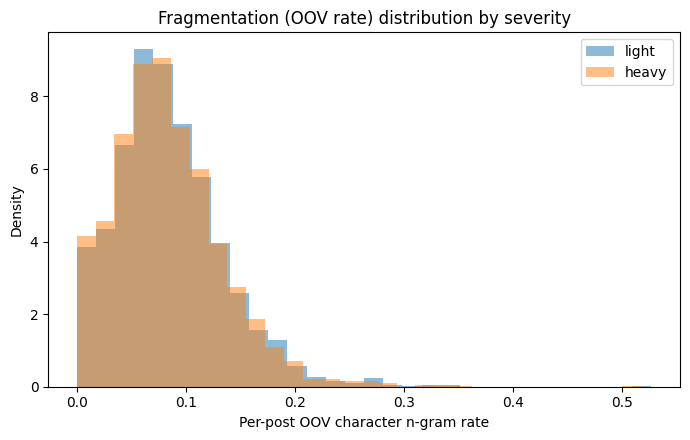

In [ ]:
oov_summary = {}
oov_by_correctness = {}

for sev in SEVERITIES:
    pipeline = all_artifacts[sev]["pipeline"]
    fitted_char_vec = pipeline.named_steps["features"].transformer_list[0][1]  # ("char_tfidf", vec)
    vocab = set(fitted_char_vec.vocabulary_.keys())
    char_analyzer = fitted_char_vec.build_analyzer()

    def oov_rate(text, vocab=vocab, analyzer=char_analyzer):
        grams = analyzer(text)
        if not grams:
            return 0.0
        unseen = sum(1 for g in grams if g not in vocab)
        return unseen / len(grams)

    test_df = analysis[sev]["test_df"]
    rates = test_df["noisy_text"].apply(oov_rate)
    analysis[sev]["oov_rate"] = rates.values

    oov_summary[sev] = rates.mean()

    correct_mask = analysis[sev]["y_pred"] == analysis[sev]["y_true"]
    oov_by_correctness[sev] = {
        "mean_oov_correct": rates[correct_mask].mean(),
        "mean_oov_incorrect": rates[~correct_mask].mean(),
    }

print("Mean OOV (unseen character n-gram) rate by severity:")
for sev, val in oov_summary.items():
    print(f"  {sev}: {val:.4f}")

print("\nMean OOV rate for correct vs. incorrect predictions, per severity:")
oov_corr_df = pd.DataFrame(oov_by_correctness).T
print(oov_corr_df)

oov_path = os.path.join(ANALYSIS_DIR, "oov_fragmentation_summary.csv")
oov_corr_df.assign(mean_oov_overall=pd.Series(oov_summary)).to_csv(oov_path)
print(f"\nSaved -> {oov_path}")

# quick visual: OOV rate distribution by severity
plt.figure(figsize=(7, 4.5))
for sev in SEVERITIES:
    plt.hist(analysis[sev]["oov_rate"], bins=30, alpha=0.5, label=sev, density=True)
plt.xlabel("Per-post OOV character n-gram rate")
plt.ylabel("Density")
plt.title("Fragmentation (OOV rate) distribution by severity")
plt.legend()
plt.tight_layout()
oov_plot_path = os.path.join(ANALYSIS_DIR, "oov_rate_distribution.png")
plt.savefig(oov_plot_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {oov_plot_path}")
plt.show()


## 18. Feature importance — actually run it for both severities

`show_top_features()` was defined back in Section 10 but never called there. Running it now (still
just inspecting the already-trained models, not retraining) gives concrete example n-grams to cite
in the paper's discussion.



LIGHT severity — top features


,feature,importance
0,char_tfidf__්කිලි,0.008176
1,char_tfidf__ හු,0.006270
2,char_tfidf__ොන්,0.005693
3,char_tfidf__සක්ක,0.005287
4,char_tfidf__වේස,0.004620
5,char_tfidf__පුක,0.004441
6,char_tfidf__හැත,0.004067
7,char_tfidf__ හැත,0.003851
8,char_tfidf__කාලක,0.003697
9,char_tfidf__ෝ,0.003664


Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/feature_importance_light.png


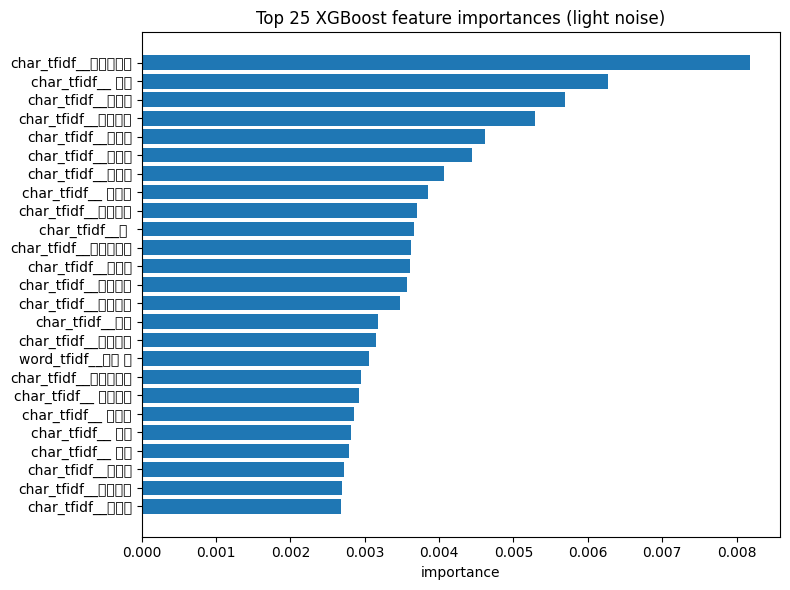

Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/feature_importance_light.csv

HEAVY severity — top features


,feature,importance
0,char_tfidf__සක්කි,0.008042
1,char_tfidf__්කිලි,0.007564
2,char_tfidf__ොන්,0.006693
3,char_tfidf__ හු,0.006459
4,char_tfidf__නොදකි,0.005217
5,char_tfidf__හැත,0.004409
6,char_tfidf__පුක,0.004386
7,char_tfidf__වේස,0.004333
8,char_tfidf__ජ්ජ,0.003833
9,char_tfidf__කාලක,0.003653


Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/feature_importance_heavy.png


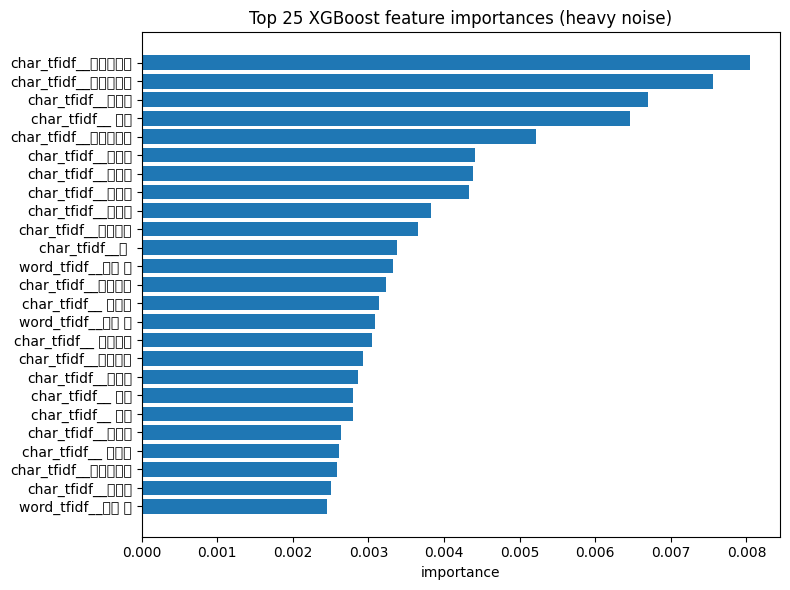

Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/feature_importance_heavy.csv


In [ ]:
feature_importance_tables = {}

for sev in SEVERITIES:
    print(f"\n{'='*50}\n{sev.upper()} severity — top features\n{'='*50}")
    pipeline = all_artifacts[sev]["pipeline"]
    feature_union = pipeline.named_steps["features"]
    model = pipeline.named_steps["clf"]

    all_names = feature_union.get_feature_names_out()
    importances = model.feature_importances_
    order = np.argsort(importances)[::-1][:25]

    top_feats = pd.DataFrame({
        "feature": all_names[order],
        "importance": importances[order],
    })
    feature_importance_tables[sev] = top_feats
    display(top_feats)

    plt.figure(figsize=(8, 6))
    plt.barh(top_feats["feature"][::-1], top_feats["importance"][::-1])
    plt.title(f"Top 25 XGBoost feature importances ({sev} noise)")
    plt.xlabel("importance")
    plt.tight_layout()
    fi_plot_path = os.path.join(ANALYSIS_DIR, f"feature_importance_{sev}.png")
    plt.savefig(fi_plot_path, dpi=150, bbox_inches="tight")
    print(f"Saved -> {fi_plot_path}")
    plt.show()

    fi_csv_path = os.path.join(ANALYSIS_DIR, f"feature_importance_{sev}.csv")
    top_feats.to_csv(fi_csv_path, index=False)
    print(f"Saved -> {fi_csv_path}")


## 19. Qualitative error analysis: sample false positives and false negatives

For the paper's discussion/error-analysis section, it helps to show a few concrete misclassified
examples rather than only aggregate numbers. This samples a few **false negatives** (offensive
posts the model missed — the more costly error type per the proposal) and **false positives**
(not-offensive posts wrongly flagged), with the model's predicted probability, for both
severities.


In [ ]:
N_EXAMPLES = 8
error_examples = {}

for sev in SEVERITIES:
    test_df = analysis[sev]["test_df"].copy()
    test_df["y_pred"] = analysis[sev]["y_pred"]
    test_df["y_proba_offensive"] = analysis[sev]["y_proba"]

    false_negatives = test_df[(test_df["label"] == 1) & (test_df["y_pred"] == 0)] \
        .sort_values("y_proba_offensive")  # most confidently (wrongly) not-offensive first
    false_positives = test_df[(test_df["label"] == 0) & (test_df["y_pred"] == 1)] \
        .sort_values("y_proba_offensive", ascending=False)  # most confidently (wrongly) offensive first

    error_examples[sev] = {
        "false_negatives": false_negatives.head(N_EXAMPLES)[["noisy_text", "y_proba_offensive"]],
        "false_positives": false_positives.head(N_EXAMPLES)[["noisy_text", "y_proba_offensive"]],
    }

    print(f"\n{'='*60}\n{sev.upper()} — {len(false_negatives)} false negatives, "
          f"{len(false_positives)} false positives total\n{'='*60}")

    print(f"\nSample false negatives (true=offensive, predicted=not-offensive), sev={sev}:")
    display(error_examples[sev]["false_negatives"])

    print(f"\nSample false positives (true=not-offensive, predicted=offensive), sev={sev}:")
    display(error_examples[sev]["false_positives"])

    fn_path = os.path.join(ANALYSIS_DIR, f"false_negatives_sample_{sev}.csv")
    fp_path = os.path.join(ANALYSIS_DIR, f"false_positives_sample_{sev}.csv")
    error_examples[sev]["false_negatives"].to_csv(fn_path, index=False)
    error_examples[sev]["false_positives"].to_csv(fp_path, index=False)
    print(f"Saved -> {fn_path}")
    print(f"Saved -> {fp_path}")



LIGHT — 273 false negatives, 176 false positives total

Sample false negatives (true=offensive, predicted=not-offensive), sev=light:


,noisy_text,y_proba_offensive
871,@USER මදි ජීවිතාන්තය දක්වා යවන්න ඕනි ඔකුන්ව.. ...,0.096114
1312,@USER @USER කරුම life ඕයි මේව්වා..,0.096362
1727,@USER පාරේ තඩි ගූ ගොඩක් දැක්කත් එකෙන් තම ස්වාම...,0.097400
1059,"@USER ටහුඩු DP එක ,මන් ඒත් බැලුවා කවුද මේ newl...",0.098924
381,@USER @USER බොලා ඔක්කොටම crazy,0.099633
1271,@USER ඇත්ත ඒ වුනාට මට ඕකිව සුවර් නැ බන්. සිහි...,0.107682
896,@USER මෙවන් අන්ධ සුනඛයින් නේන්නම් ඔහෙලගේ chann...,0.114765
1224,@USER ඔව් මට මතකයි. දවසක් මන් බණ ගෙදරක ගිය වේල...,0.119124



Sample false positives (true=not-offensive, predicted=offensive), sev=light:


,noisy_text,y_proba_offensive
306,@USER උබල සෙරම පටු අරමුනු සහ කාලකණ්ණි politici...,0.983134
2220,@USER @USER යකූ second හුජ්ජ කරන්නෙ මං,0.964359
822,"@USER , @USER @USER අනික බන් මේ දවස්වල රට හර...",0.944595
2028,පෙති ගසල සුදිය දාන ගමන් වේස modeling සිල් පිනි...,0.944554
1106,දෙමළ ඩයස්පෝරාව උන් ඉන්න රටේ පාලයකයා තමන්ගේ මව්...,0.940449
1514,@USER අපිට නම් කණ පැලෙන්න hit කරන්න දෙම්ව්පියෝ...,0.939940
53,නොදකින් කකුලා හරකා ඌරා ගැන මේකේ ඉන්න කෙල්ලන්ට ...,0.937312
398,- අය්යේ ඉස්සරහා හුඹහා ගාවින් බස්සලා යන්න - තමු...,0.924786


Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/false_negatives_sample_light.csv
Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/false_positives_sample_light.csv

HEAVY — 273 false negatives, 184 false positives total

Sample false negatives (true=offensive, predicted=not-offensive), sev=heavy:


,noisy_text,y_proba_offensive
381,@USER @USER බොලා ඔක්කොටම crazy,0.091039
1312,@USER @USER කරුම life ඕයි මේව්වා..,0.098209
1059,"@USER ටහුඩු DP එක ,මන් ඒත් බැලුවා කවුද මේ newl...",0.102721
2282,නයිටි එකක් ඇඳගත්ත sister කෙනෙක් දාපු crazy හැද...,0.107420
2238,good governance එකට vote එක දුන් ඔබටත් ඔබෙ දරැ...,0.113857
965,"@USER @USER good governance මල්ලිලගේ mouths, ...",0.128150
871,@USER මදි ජීවිතාන්තය දක්වා යවන්න ඕනි ඔකුන්ව.. ...,0.134402
1156,@USER @USER අැයි‍ බොල උට්ටො tooth එකේ proble...,0.134475



Sample false positives (true=not-offensive, predicted=offensive), sev=heavy:


,noisy_text,y_proba_offensive
2220,@USER @USER යකූ second හුජ්ජ කරන්නෙ මං,0.974564
306,@USER උබල සෙරම පටු අරමුනු සහ කාලකණ්ණි politici...,0.973579
2028,පෙති ගසල සුදිය දාන ගමන් වේස modeling සිල් පිනි...,0.959775
1106,දෙමළ ඩයස්පෝරාව උන් ඉන්න country එකේ පාලයකයා තම...,0.931140
53,නොදකින් කකුලා හරකා ඌරා ගැන මේකේ ඉන්න කෙල්ලන්ට ...,0.931132
1506,@USER බුද්ධාගමේ එවුන් ඇය් දේවාලේ ලගින්නේ බුදු...,0.926710
751,පකෝ පව් යකෝ Channa Lakshitha @USER · 8 Nov 2...,0.925638
822,"@USER , @USER @USER අනික බන් මේ days වල රට හ...",0.919133


Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/false_negatives_sample_heavy.csv
Saved -> /content/drive/MyDrive/codemix/results/xgboost/analysis/false_positives_sample_heavy.csv


## Summary of what this section adds for the paper

- **Confusion matrix heatmaps** — drop-in figures for the Results section.
- **ROC/PR curves + AUC/AP** — standard threshold-independent metrics to report alongside macro-F1.
- **Bootstrap 95% CIs on macro-F1** — a lightweight stand-in for the proposal's multi-seed
  confidence intervals (Section 5.4.1), without retraining.
- **McNemar's exact test (light vs. heavy, matched by post)** — a direct statistical answer to
  "is the light-vs-heavy macro-F1 difference real, or could it be chance?" (Section 5.4.1).
- **OOV/fragmentation rate analysis** — a concrete, measurable proxy for the tokenization
  fragmentation discussion in Section 5.4.2, comparable across severities and between
  correct/incorrect predictions.
- **Feature importances, actually run** — concrete example n-grams for the discussion section.
- **Sampled qualitative errors** — real false-positive/false-negative examples to quote or discuss.

All outputs are saved under `results/xgboost/analysis/` in your Drive alongside the existing
`results/xgboost/` outputs from Sections 1–11, so nothing gets overwritten.

**Nothing above changes any previously reported number** — Sections 12 onward only *read* the
already-fitted pipelines and already-loaded data to compute additional views on the same
underlying predictions.
